In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import load_config, resolve_path
from src.data.loader import (
    SENSOR_COLS,
    SETTING_COLS,
    add_rul_target,
    load_cmapss_file,
    split_by_engine,
)

sns.set_theme(style="whitegrid")

cfg = load_config()
raw_df = load_cmapss_file(resolve_path(cfg["paths"]["raw_train"]))

# Keep RUL unclipped first so we can visually discover the degradation elbow
raw_df = add_rul_target(raw_df, clip_max=None)

train_df, _ = split_by_engine(
    raw_df,
    val_size=cfg["data"]["val_size"],
    random_seed=cfg["data"]["random_seed"],
)

print(f"EDA set: {len(train_df):,} rows across {train_df['unit_id'].nunique()} engines")
train_df.head(3)

EDA set: 16,561 rows across 80 engines


,unit_id,cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,2,1,-0.0018,0.0006,100.0,518.67,641.89,1583.84,1391.28,14.62,...,2388.06,8137.72,8.3905,0.03,391,2388,100.0,38.94,23.4585,286
1,2,2,0.0043,-0.0003,100.0,518.67,641.82,1587.05,1393.13,14.62,...,2387.98,8131.09,8.4167,0.03,392,2388,100.0,39.06,23.4085,285
2,2,3,0.0018,0.0003,100.0,518.67,641.55,1588.32,1398.96,14.62,...,2387.99,8140.58,8.3802,0.03,391,2388,100.0,39.11,23.4250,284


count     80.0
mean     207.0
std       47.5
min      128.0
25%      179.8
50%      199.0
75%      216.2
max      362.0
Name: cycle, dtype: float64


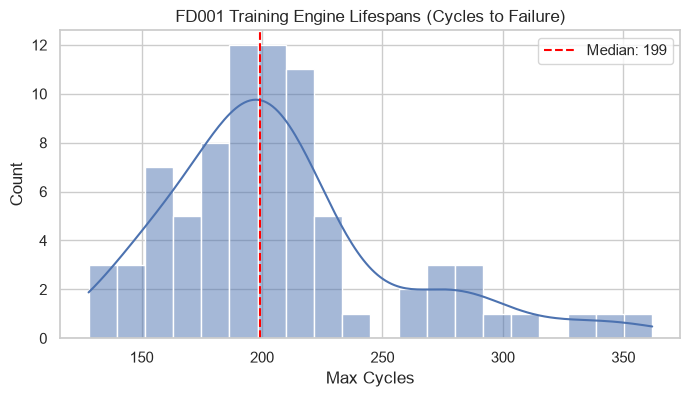

In [2]:
engine_lifespans = train_df.groupby("unit_id")["cycle"].max()
print(engine_lifespans.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(engine_lifespans, bins=20, kde=True, ax=ax)
ax.axvline(engine_lifespans.median(), color="red", linestyle="--", label=f"Median: {engine_lifespans.median():.0f}")
ax.set_title("FD001 Training Engine Lifespans (Cycles to Failure)")
ax.set_xlabel("Max Cycles")
ax.legend()
plt.show()

In [3]:
feature_cols = SETTING_COLS + SENSOR_COLS
stats = pd.DataFrame({
    "mean": train_df[feature_cols].mean(),
    "std": train_df[feature_cols].std(),
    "min": train_df[feature_cols].min(),
    "max": train_df[feature_cols].max(),
    "n_unique": train_df[feature_cols].nunique(),
}).sort_values("std")

stats

,mean,std,min,max,n_unique
s1,518.670000,0.000000e+00,518.6700,518.6700,1
op_setting_3,100.000000,0.000000e+00,100.0000,100.0000,1
s18,2388.000000,0.000000e+00,2388.0000,2388.0000,1
s19,100.000000,0.000000e+00,100.0000,100.0000,1
s16,0.030000,1.040866e-17,0.0300,0.0300,1
s10,1.300000,2.220513e-16,1.3000,1.3000,1
s5,14.620000,5.329231e-15,14.6200,14.6200,1
op_setting_2,0.000002,2.926411e-04,-0.0006,0.0006,13
s6,21.609810,1.363886e-03,21.6000,21.6100,2
op_setting_1,-0.000007,2.190658e-03,-0.0087,0.0087,156


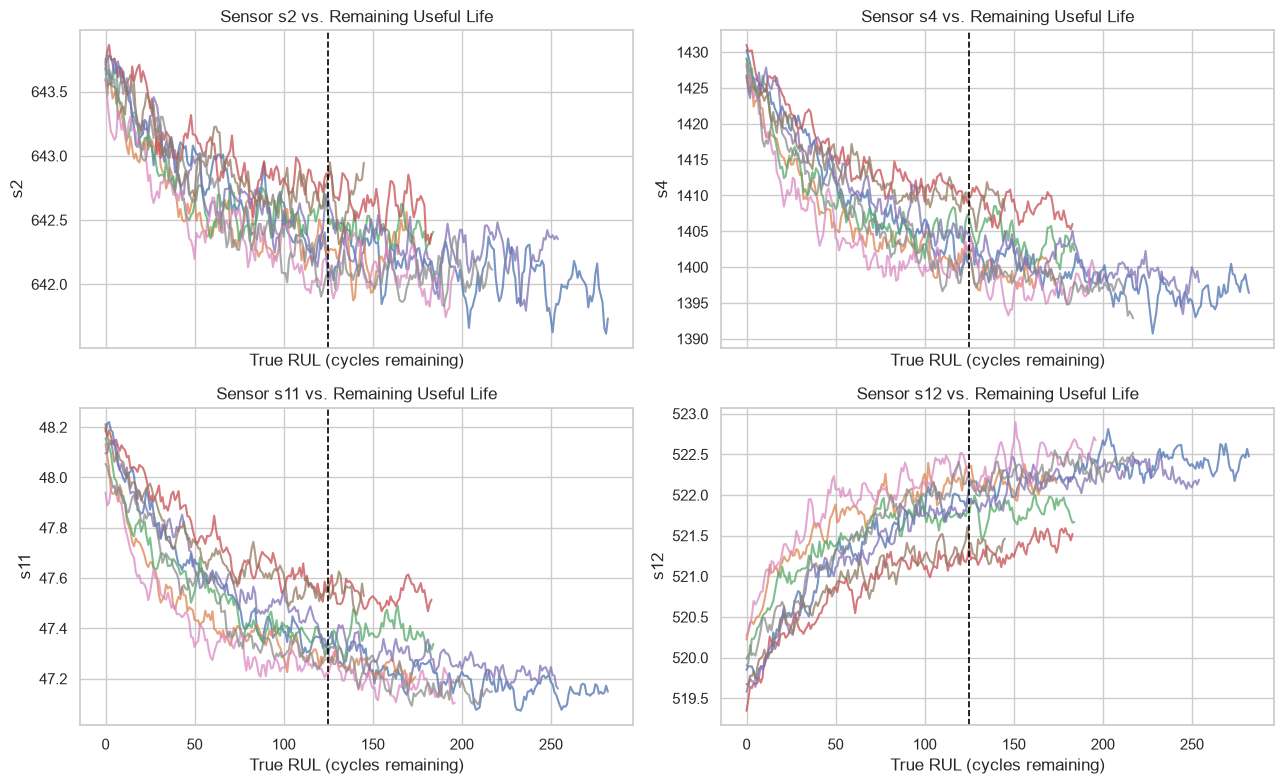

In [4]:
sample_units = train_df["unit_id"].unique()[:8]
sample_df = train_df[train_df["unit_id"].isin(sample_units)]

# Four informative sensors from different engine stages
sensors_to_plot = ["s2", "s4", "s11", "s12"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, sensor in zip(axes.flat, sensors_to_plot):
    for uid, grp in sample_df.groupby("unit_id"):
        # Light rolling mean just to make the underlying trend easy to see
        ax.plot(grp["RUL"], grp[sensor].rolling(5).mean(), alpha=0.75, label=f"Unit {uid}")
    ax.axvline(125, color="black", linestyle="--", linewidth=1.2, label="RUL = 125")
    ax.invert_xaxis()  # Left = early life (high RUL), Right = failure (RUL = 0)
    ax.set_title(f"Sensor {sensor} vs. Remaining Useful Life")
    ax.set_xlabel("True RUL (cycles remaining)")
    ax.set_ylabel(sensor)

plt.tight_layout()
plt.show()

In [5]:
unclipped_corr = train_df[SENSOR_COLS].corrwith(train_df["RUL"], method="spearman")
clipped_rul = train_df["RUL"].clip(upper=125)
clipped_corr = train_df[SENSOR_COLS].corrwith(clipped_rul, method="spearman")

corr_df = pd.DataFrame({
    "corr_unclipped": unclipped_corr,
    "corr_clipped_125": clipped_corr,
}).dropna()

corr_df["abs_clipped"] = corr_df["corr_clipped_125"].abs()
corr_df.sort_values("abs_clipped", ascending=False).drop(columns="abs_clipped").round(3)

c:\Development\turbofan-rul-engine\.venv\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
c:\Development\turbofan-rul-engine\.venv\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,corr_unclipped,corr_clipped_125
s11,-0.708,-0.712
s4,-0.690,-0.695
s12,0.680,0.685
s7,0.667,0.673
s15,-0.656,-0.662
s20,0.645,0.653
s21,0.647,0.652
s17,-0.621,-0.629
s2,-0.620,-0.624
s3,-0.598,-0.604
